# Module 5 — Notebook 01: Kinchen 2018 human colon (load + QC)

**Why this cohort first.** Kinchen et al. (Cell 2018) is the keystone of the
cross-cohort paper: one GEO series (GSE114374) carries human healthy + UC colon
AND mouse healthy + DSS colon from the same lab. This notebook loads the two
human matrices; the mouse arm gets its own notebook.

**Question carried over from module 1.** Does an IL11/IL13RA2-high inflammatory
fibroblast population appear in UC here too, and where do the OSM/OSMR and
SIGIRR readouts sit?

**Caution.** These GEO matrices are the authors' processed expression values —
the first cells inspect orientation and value type (counts vs normalized)
before any QC gate is applied.

Analyses of public datasets; all data credited to original authors.


In [8]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scanpy as sc

base = os.path.expanduser("~/Documents/immune-endotypes/data/kinchen_2018")
for f in ["GSE114374_Human_HC_expression_matrix.txt.gz",
          "GSE114374_Human_UC_expression_matrix.txt.gz"]:
    p = os.path.join(base, f)
    print(f, "exists:", os.path.exists(p), os.path.getsize(p) // 10**6 if os.path.exists(p) else "-", "MB")


GSE114374_Human_HC_expression_matrix.txt.gz exists: True 74 MB
GSE114374_Human_UC_expression_matrix.txt.gz exists: True 117 MB


In [9]:
# Orientation + value inspection on the healthy matrix (first 2000 columns only)
peek = pd.read_csv(os.path.join(base, "GSE114374_Human_HC_expression_matrix.txt.gz"),
                   sep="\t", index_col=0, nrows=2000)
print("peek shape (rows x cols):", peek.shape)
print("index head:", list(peek.index[:5]))
print("columns head:", list(peek.columns[:5]))
vals = peek.values
print("value range:", np.nanmin(vals), "->", np.nanmax(vals))
print("non-integer share:", float(np.mean(np.abs(vals - np.round(vals)) > 1e-6)))


peek shape (rows x cols): (2000, 4378)
index head: ['RP11-34P13.3', 'FAM138A', 'OR4F5', 'RP11-34P13.7', 'RP11-34P13.8']
columns head: ['AAACCTGCAAGGACTG-S66', 'AAACCTGCACAACTGT-S66', 'AAACCTGCACCCTATC-S66', 'AAACCTGCAGGCTCAC-S66', 'AAACCTGCAGTCTTCC-S66']
value range: 0.0 -> 6.09472675459859
non-integer share: 0.06512894015532207


Decide from the peek: if rows are genes (index = gene symbols, ~20-30k rows
in the full file) the matrix is genes x cells and gets transposed below. If the
values are continuous with a modest max, they are normalized expression, not raw
counts — QC then uses detected-gene counts, and no second normalization is applied.


In [10]:
def load_matrix(fname, condition):
    df = pd.read_csv(os.path.join(base, fname), sep="\t", index_col=0)
    # GEO matrices from this series are genes x cells -> transpose to cells x genes
    ad = sc.AnnData(df.T)
    ad.obs["condition"] = condition
    ad.obs["sample"] = [c.rsplit("-", 1)[-1] for c in ad.obs_names]  # barcode suffix = source sample (e.g. S66)
    ad.obs["dataset"] = "Kinchen2018"
    ad.var_names_make_unique()
    return ad

hc = load_matrix("GSE114374_Human_HC_expression_matrix.txt.gz", "Healthy")
uc = load_matrix("GSE114374_Human_UC_expression_matrix.txt.gz", "UC")
print(hc.shape, uc.shape)
adata = sc.concat([hc, uc], join="outer")
adata.obs_names_make_unique()
print(adata)
print(adata.obs["condition"].value_counts())


(4378, 33694) (4903, 33694)
AnnData object with n_obs × n_vars = 9281 × 33694
    obs: 'condition', 'sample', 'dataset'
condition
UC         4903
Healthy    4378
Name: count, dtype: int64


In [11]:
# QC on detected genes (works for counts or normalized values)
sc.pp.calculate_qc_metrics(adata, inplace=True, percent_top=None)
print(adata.obs[["n_genes_by_counts", "total_counts"]].describe())
adata = adata[adata.obs["n_genes_by_counts"] > 200].copy()
sc.pp.filter_genes(adata, min_cells=3)
print("after QC:", adata.shape)


       n_genes_by_counts  total_counts
count        9281.000000   9281.000000
mean         2262.621377   2682.846708
std          1045.785064    559.444406
min            47.000000    132.779569
25%          1567.000000   2416.445473
50%          2061.000000   2739.626438
75%          2701.000000   3035.286594
max          8944.000000   4231.585661
after QC: (9271, 21171)


In [12]:
# Standard embedding (module 1 template). If the values were already normalized,
# scanpy's normalize_total/log1p are skipped automatically by the check cell logic:
vmax = float(adata.X.max())
if vmax > 50:  # count-like
    adata.layers["counts"] = adata.X.copy()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
else:
    print("values look pre-normalized (max =", round(vmax, 2), ") — using as-is")
sc.pp.highly_variable_genes(adata, n_top_genes=3000, batch_key="condition")
sc.tl.pca(adata, n_comps=50)
sc.pp.neighbors(adata, n_pcs=40)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5, key_added="leiden_0.5")
print("leiden clusters:", adata.obs["leiden_0.5"].nunique())


values look pre-normalized (max = 8.64 ) — using as-is
leiden clusters: 15


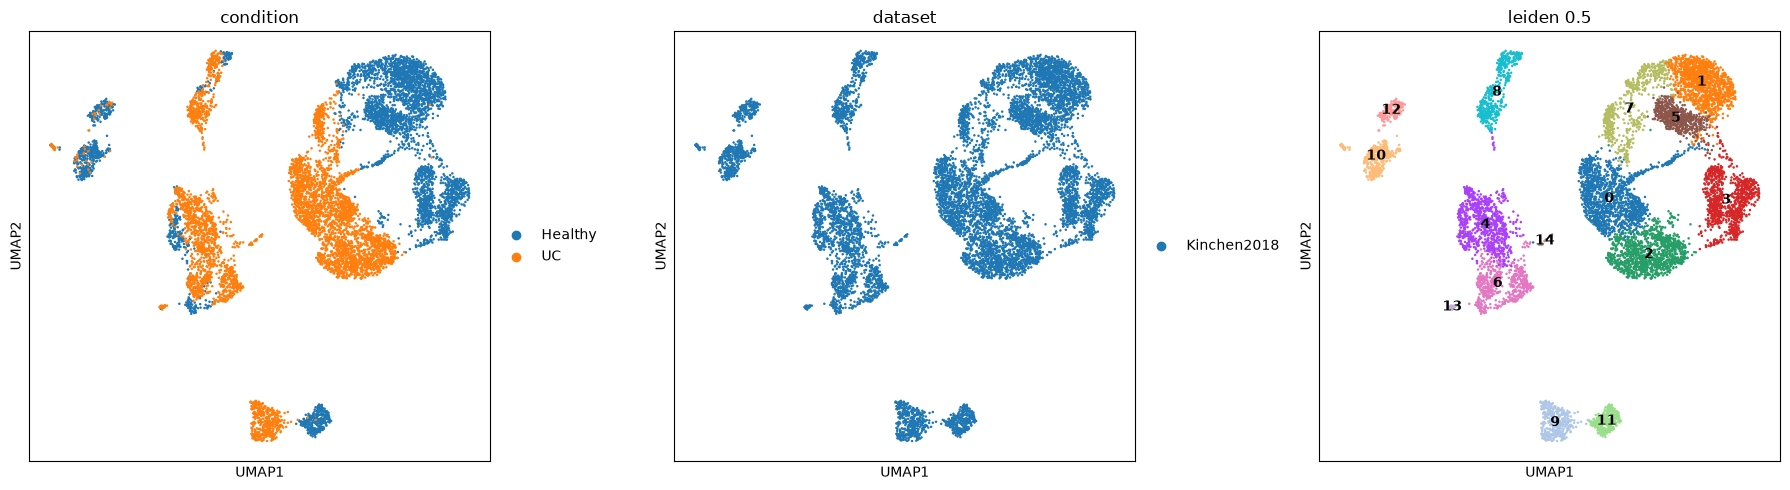

In [13]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sc.pl.umap(adata, color="condition", ax=axes[0], show=False, title="condition")
sc.pl.umap(adata, color="dataset", ax=axes[1], show=False, title="dataset")
sc.pl.umap(adata, color="leiden_0.5", ax=axes[2], show=False, title="leiden 0.5", legend_loc="on data")
plt.tight_layout()
plt.savefig("../figures/kinchen_human_umap_overview.png", dpi=130)
plt.show()


markers present: ['EPCAM', 'COL1A1', 'DCN', 'PECAM1', 'PTPRC', 'CD3D', 'JCHAIN', 'LYZ', 'S100A8']


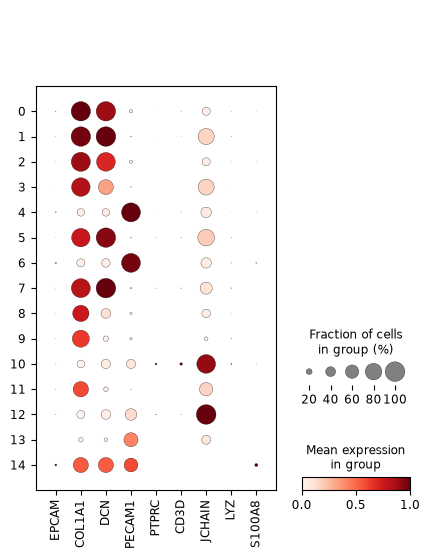

In [14]:
# First-pass compartment check: canonical markers by cluster.
# The fibroblast compartment (COL1A1/DCN) is where the module 1 circuit lives.
markers = ["EPCAM", "MUC2", "CHGA", "COL1A1", "DCN", "PECAM1",
           "PTPRC", "CD3D", "MS4A1", "JCHAIN", "LYZ", "S100A8"]
present = [g for g in markers if g in adata.var_names]
print("markers present:", present)
sc.pl.dotplot(adata, present, groupby="leiden_0.5", standard_scale="var")


watch genes present: ['IL11', 'IL13RA2', 'CHI3L1', 'OSMR', 'OSM', 'SIGIRR', 'IL1B', 'IL1R1', 'MMP3']


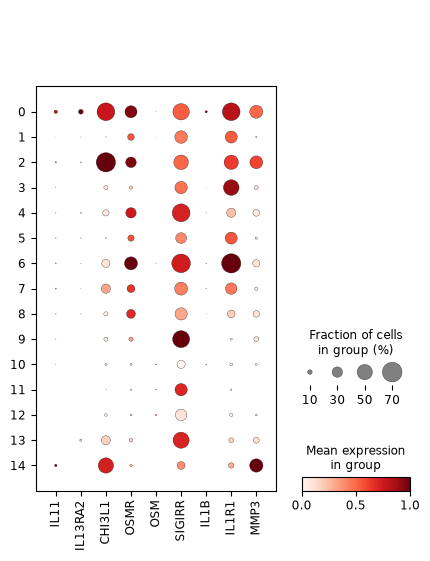

saved adata_kinchen_human_qc.h5ad


In [15]:
# Fibroblast-circuit watch genes, per cluster (mean expression)
watch = ["IL11", "IL13RA2", "CHI3L1", "OSMR", "OSM", "SIGIRR", "IL1B", "IL1R1", "MMP3"]
watch = [g for g in watch if g in adata.var_names]
print("watch genes present:", watch)
sc.pl.dotplot(adata, watch, groupby="leiden_0.5", standard_scale="var")
adata.write(os.path.expanduser("~/Documents/immune-endotypes/data/kinchen_2018/adata_kinchen_human_qc.h5ad"))
print("saved adata_kinchen_human_qc.h5ad")


## Read-out (fill in after running)

- Which leiden clusters are the fibroblast compartment, and does a UC-enriched
  IL11/IL13RA2-high cluster appear (the Kinchen counterpart of Smillie's
  inflammatory fibroblasts)?
- Where do OSMR and SIGIRR sit in this cohort?
- Next: notebook 02 — Martin CD load/QC; notebook 03 — human integration
  (scVI, dataset as batch) + label harmonization; notebook 04 — per-cohort
  circuit replication; notebook 05 — Kinchen mouse arm, cross-species scoring.
